# Emoji vendor classification
## STEP 1 : Install and import libraries

In [1]:
! pip install scikit-image
! pip install matplotlib
! pip install numpy
! pip install pandas
! pip install scikit-learn
! pip install torch torchvision

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/12.0 MB ? eta -:--:--

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 79.1 MB/s  0:00:00


   ━━━━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━ 2/4 [imageio]

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╺━━━━━━━━━ 3/4 [scikit-image]

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [scikit-image]


...


[notice] A new release of pip is available: 26.0 -> 26.2.1
[notice] To update, run: pip install --upgrade pip



[notice] A new release of pip is available: 26.0 -> 26.2.1
[notice] To update, run: pip install --upgrade pip



[notice] A new release of pip is available: 26.0 -> 26.2.1
[notice] To update, run: pip install --upgrade pip



[notice] A new release of pip is available: 26.0 -> 26.2.1
[notice] To update, run: pip install --upgrade pip



[notice] A new release of pip is available: 26.0 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [2]:
import os
import numpy as np
import pandas as pd
from pathlib import Path
from skimage import io
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.model_selection import train_test_split

## STEP 2 : Import and parse the data

For this local VS Code setup, the dataset is read from the project folder.


The Kaggle download step is not needed here because the dataset is already in the project folder:

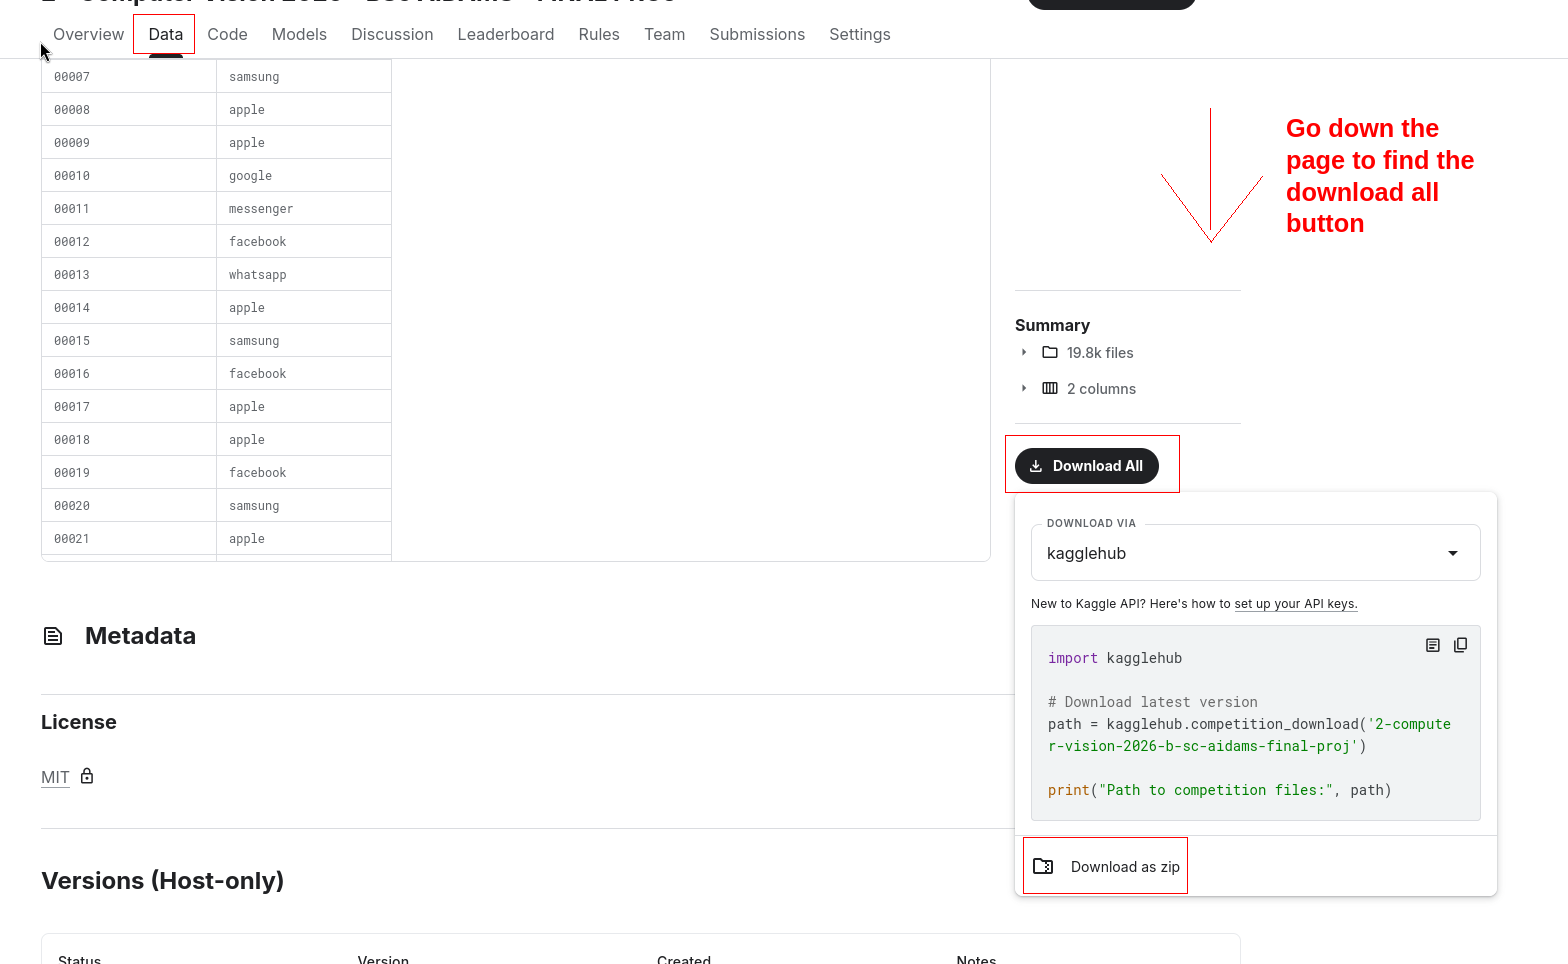

The dataset is already available in the project folder. The next cell sets the local dataset path.

In [3]:
! pwd

/Users/charlesmontluc/Downloads/CompVisionFinalProj


Run the following command to see the train / test dataset appear, as well as the train labels

In [4]:
from pathlib import Path

DATA_DIR = Path.cwd() / "2-computer-vision-2026-b-sc-aidams-final-proj"
if not DATA_DIR.is_dir():
    raise FileNotFoundError(f"Dataset folder not found: {DATA_DIR}")

print(f"Using local dataset: {DATA_DIR}")

Using local dataset: /Users/charlesmontluc/Downloads/CompVisionFinalProj/2-computer-vision-2026-b-sc-aidams-final-proj


The following code will run through a dataset and show you the different files of the training dataset :

In [5]:
for dirname, _, filenames in os.walk(DATA_DIR / 'train'):
    for filename in filenames[:5]: # I print 5 files per folder
        print(os.path.join(dirname, filename))


/Users/charlesmontluc/Downloads/CompVisionFinalProj/2-computer-vision-2026-b-sc-aidams-final-proj/train/07488.png
/Users/charlesmontluc/Downloads/CompVisionFinalProj/2-computer-vision-2026-b-sc-aidams-final-proj/train/06796.png
/Users/charlesmontluc/Downloads/CompVisionFinalProj/2-computer-vision-2026-b-sc-aidams-final-proj/train/08963.png
/Users/charlesmontluc/Downloads/CompVisionFinalProj/2-computer-vision-2026-b-sc-aidams-final-proj/train/03836.png
/Users/charlesmontluc/Downloads/CompVisionFinalProj/2-computer-vision-2026-b-sc-aidams-final-proj/train/04181.png


### Function definition

In [6]:
def show_img(imgs, titles, gray=False, length=None, array_of_array=False):
    """
    Input : - imgs : list of np.arrays of images (or one np.array)
            - titles : list of strings (or one string)

    Description : Plots the images in a row with their corresponding titles.
                  If one image : only plots one image.

    Returns : None
    """
    if not array_of_array:
        if type(imgs) != list:
            imgs = [imgs]
    if type(titles) != list:
        titles = [titles]

    if len(imgs) != len(titles):
        raise ValueError(
            f"""You provided {len(imgs)} images and {len(titles)} titles.
                         Please provide equal number of images and titles."""
        )
    nb_imgs = len(imgs)
    if length:
        plt.figure(figsize=(length, 6))
    else:
        plt.figure()
    for i, (img, title) in enumerate(zip(imgs, titles)):
        plt.subplot(1, nb_imgs, i + 1)
        if gray:
            plt.imshow(img, cmap="gray")
        else:
            plt.imshow(img)
        plt.title(title)
        plt.axis("off")
    plt.show()

In [7]:
IMG_SIZE = 160
IMAGE_MODES = ["RGBA", "P", "LA", "RGB", "L"]


def load_data(folder_path: str):
    path_to_images = Path(folder_path)
    if not path_to_images.is_dir():
        raise FileNotFoundError(f"Image folder not found: {path_to_images}")

    image_files = sorted(
        file_path
        for file_path in path_to_images.iterdir()
        if file_path.is_file() and file_path.suffix.lower() in {".png", ".jpg", ".jpeg"}
    )
    if not image_files:
        raise ValueError(f"No image files found in {path_to_images}")

    ids = [file_path.stem for file_path in image_files]
    dataset, meta, formats = [], [], []

    for img_file in image_files:
        img = Image.open(img_file)
        width, height = img.size

        # The original file format (colour mode and resolution) differs between vendors
        formats.append(f"{img.mode}{img.size}")
        meta.append([img.mode == mode for mode in IMAGE_MODES] + [width / 240, height / 240, float(width == height)])

        # Flatten transparency onto a white background and keep the colour channels
        img = img.convert("RGBA")
        background = Image.new("RGBA", img.size, (255, 255, 255, 255))
        img = Image.alpha_composite(background, img).convert("RGB")
        img = img.resize((IMG_SIZE, IMG_SIZE), Image.BICUBIC)
        dataset.append(np.asarray(img, dtype=np.uint8))

    return np.stack(dataset), ids, np.asarray(meta, dtype=np.float32), np.asarray(formats)

##  STEP 3 : Data Analysis
### Getting the shapes

This cell will return an error at first : it is normal, the preprocessing given as an example is incorrect on the cell above. It is part of the challenge to find the correct pre processing and loading of the data for the model as it has an impact on the performance.

In [8]:
X_train, X_train_ids, M_train, fmt_train = load_data(DATA_DIR / "train")
print("Shape of train dataset", X_train.shape)

X_test, X_test_ids, M_test, fmt_test = load_data(DATA_DIR / "test")
print("Shape of test dataset", X_test.shape)

y_train = pd.read_csv(DATA_DIR / "train_labels.csv", dtype={"Id": str})
y_train["Id"] = y_train["Id"].str.zfill(5)
y_train = y_train.set_index("Id").loc[X_train_ids].reset_index()
print("Shape of predictions for train dataset", y_train.shape)

Shape of train dataset (9879, 160, 160, 3)


Shape of test dataset (9879, 160, 160, 3)
Shape of predictions for train dataset (9879, 2)


### Showing example observations

In [9]:
X_train_ids[:3]

['00001', '00002', '00003']

In [10]:
y_train.head(3)

,Id,Label
0,00001,samsung
1,00002,apple
2,00003,facebook


In [11]:
number_of_images_to_display = 10
selected_titles = [f"ID: {img_id}\nTrue value: {img_label}" for img_id, img_label in zip(X_train_ids, y_train["Label"])][:number_of_images_to_display]
selected_imgs = X_train[:number_of_images_to_display]
selected_imgs.shape

(10, 160, 160, 3)

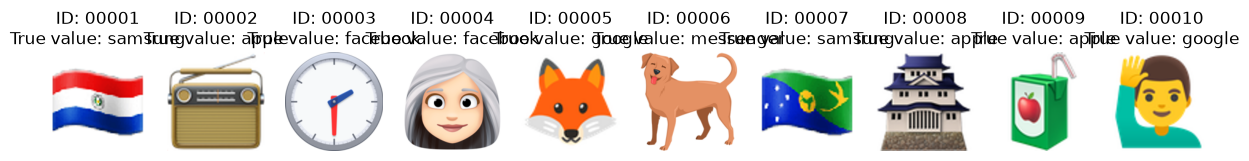

In [12]:
show_img(list(selected_imgs), selected_titles, length=15)

## STEP 4 : Train a model on the training dataset

A ResNet18 pretrained on ImageNet is fine-tuned on the RGB images. The original file format of each image is given to the classifier head as extra features. 15% of the training set is held out for validation.

In [13]:
torch.manual_seed(0)
np.random.seed(0)
device = "mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu"

classes = sorted(y_train["Label"].unique())
y = torch.tensor(y_train["Label"].map({c: i for i, c in enumerate(classes)}).to_numpy())
X_tr_t = torch.from_numpy(X_train).permute(0, 3, 1, 2).contiguous()
M_tr_t = torch.from_numpy(M_train)

train_idx, val_idx = train_test_split(np.arange(len(y)), test_size=0.15, stratify=y, random_state=0)

MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)


def preprocess(xb, augment):
    xb = xb.to(device).float() / 255
    if augment:
        # Random horizontal flip plus a small random zoom and shift (no colour changes)
        flip = torch.rand(len(xb), device=device) < 0.5
        xb[flip] = xb[flip].flip(3)
        theta = torch.zeros(len(xb), 2, 3, device=device)
        scale = 1 + (torch.rand(len(xb), device=device) - 0.5) * 0.2
        theta[:, 0, 0] = scale
        theta[:, 1, 1] = scale
        theta[:, :, 2] = (torch.rand(len(xb), 2, device=device) - 0.5) * 0.15
        grid = F.affine_grid(theta, xb.shape, align_corners=False)
        xb = F.grid_sample(xb, grid, padding_mode="border", align_corners=False)
    return (xb - MEAN) / STD


class EmojiNet(nn.Module):
    def __init__(self, n_meta, n_classes):
        super().__init__()
        self.cnn = resnet18(weights=ResNet18_Weights.DEFAULT)
        self.cnn.fc = nn.Identity()
        self.fc = nn.Sequential(nn.Dropout(0.2), nn.Linear(512 + n_meta, n_classes))

    def forward(self, x, meta):
        return self.fc(torch.cat([self.cnn(x), meta * 4], 1))


def predict_proba(model, X_t, M_t, idx):
    # Averages the predictions on each image and its mirrored copy
    model.eval()
    probs = []
    with torch.no_grad():
        for i in range(0, len(idx), 256):
            xb = preprocess(X_t[idx[i:i + 256]], augment=False)
            mb = M_t[idx[i:i + 256]].to(device)
            probs.append(((model(xb, mb).softmax(1) + model(xb.flip(3), mb).softmax(1)) / 2).cpu())
    return torch.cat(probs).numpy()


model = EmojiNet(M_train.shape[1], len(classes)).to(device)
EPOCHS, BATCH_SIZE = 20, 64
optimizer = torch.optim.AdamW(model.parameters(), lr=5e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=5e-4, total_steps=EPOCHS * ((len(train_idx) + BATCH_SIZE - 1) // BATCH_SIZE)
)
class_weights = torch.tensor(len(y) / (len(classes) * np.bincount(y.numpy())), dtype=torch.float32, device=device)
criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.1)

for epoch in range(EPOCHS):
    model.train()
    perm = np.random.permutation(train_idx)
    for i in range(0, len(perm), BATCH_SIZE):
        b = perm[i:i + BATCH_SIZE]
        loss = criterion(model(preprocess(X_tr_t[b], augment=True), M_tr_t[b].to(device)), y[b].to(device))
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        scheduler.step()
    val_acc = (predict_proba(model, X_tr_t, M_tr_t, val_idx).argmax(1) == y[val_idx].numpy()).mean()
    print(f"Epoch {epoch + 1}/{EPOCHS} - validation accuracy {val_acc:.4f}")

Epoch 1/20 - validation accuracy 0.8387


Epoch 2/20 - validation accuracy 0.8637


Epoch 3/20 - validation accuracy 0.9130


Epoch 4/20 - validation accuracy 0.7085


Epoch 5/20 - validation accuracy 0.9076


...

Epoch 16/20 - validation accuracy 0.9399


Epoch 17/20 - validation accuracy 0.9184


Epoch 18/20 - validation accuracy 0.9379


Epoch 19/20 - validation accuracy 0.9440


Epoch 20/20 - validation accuracy 0.9440


### Combining the CNN with the file-format statistics

Some vendors look very similar (for example Facebook and WhatsApp) but are stored in different file formats. The CNN probabilities are multiplied by the class frequencies observed for each file format in the training split, divided by the overall class frequencies.

In [14]:
y_np = y.numpy()
class_prior = np.bincount(y_np[train_idx], minlength=len(classes)) / len(train_idx)
format_table = {}
for f in np.unique(np.concatenate([fmt_train, fmt_test])):
    counts = np.bincount(y_np[train_idx][fmt_train[train_idx] == f], minlength=len(classes))
    format_table[f] = (counts + class_prior) / (counts.sum() + 1)


def combine_with_format(cnn_probs, formats):
    format_probs = np.stack([format_table[f] for f in formats])
    return (cnn_probs * format_probs / class_prior).argmax(1)


val_probs = predict_proba(model, X_tr_t, M_tr_t, val_idx)
print("Validation accuracy (CNN only):", (val_probs.argmax(1) == y_np[val_idx]).mean())
val_pred = combine_with_format(val_probs, fmt_train[val_idx])
print("Validation accuracy (CNN + file format):", (val_pred == y_np[val_idx]).mean())
pd.crosstab(np.array(classes)[y_np[val_idx]], np.array(classes)[val_pred], rownames=["true"], colnames=["predicted"])

Validation accuracy (CNN only): 0.9439946018893387
Validation accuracy (CNN + file format): 0.9635627530364372


predicted,apple,facebook,google,messenger,mozilla,samsung,whatsapp
true,,,,,,,
apple,283,0,6,0,0,0,0
facebook,7,229,2,2,10,0,0
google,5,0,277,0,0,0,0
messenger,0,0,0,81,5,1,0
mozilla,1,0,0,2,56,0,0
samsung,5,0,2,0,0,261,0
whatsapp,3,0,2,0,0,1,241


## STEP 5 : Make predictions

In [15]:
def predict_with_my_amazing_model(X_test):
    X_te_t = torch.from_numpy(X_test).permute(0, 3, 1, 2).contiguous()
    M_te_t = torch.from_numpy(M_test)
    test_probs = predict_proba(model, X_te_t, M_te_t, np.arange(len(X_test)))
    return np.array(classes)[combine_with_format(test_probs, fmt_test)]

In [16]:
y_test_pred = predict_with_my_amazing_model(X_test)

In [17]:
y_test_pred

array(['google', 'messenger', 'samsung', ..., 'apple', 'google', 'apple'],
      shape=(9879,), dtype='<U9')

In [18]:
X_test_ids_sr = pd.Series(X_test_ids, name="Id")
y_test_pred_sr = pd.Series(y_test_pred, name="Label")
submission_df = pd.concat([X_test_ids_sr, y_test_pred_sr], axis=1)

In [19]:
submission_df.head()

,Id,Label
0,10001,google
1,10002,messenger
2,10003,samsung
3,10004,whatsapp
4,10005,samsung


In [20]:
submission_df.to_csv("submission.csv", index=False)